### Setup inicial (Importaciones y Modelo)
Para que este notebook sea independiente y no lance errores de variables no definidas, ejecutamos primero la configuración básica y simulamos un modelo global.

In [28]:
from utils import *
import copy
import matplotlib.pyplot as plt
import numpy as np

In [29]:
# --- CARGA DEL MODELO DEL EJERCICIO 2 ---
# En lugar de entrenar uno nuevo, cargamos el modelo global real del ejercicio anterior.
import os
global_model = SimpleCNN().to(device)

if os.path.exists('global_model_ej2.pth'):
    global_model.load_state_dict(torch.load('global_model_ej2.pth', map_location=device, weights_only=True))
    print('Modelo global del Ejercicio 2 cargado correctamente.')
else:
    print('Error: No se encuentra global_model_ej2.pth. ¡Asegúrate de ejecutar el Notebook 2 primero!')


Modelo global del Ejercicio 2 cargado correctamente.


# 5. Ataque de Inferencia de Membresía (MIA)
### ¿En qué consiste y cómo funciona el ataque de inferencia de membresía (MIA)?
El ataque de inferencia de membresía tiene como objetivo determinar si un registro específico fue utilizado durante el entrenamiento de un modelo de Machine Learning.
Funciona explotando la diferencia de confianza del modelo al predecir datos con los que ha sido entrenado (donde suele tener alta confianza debido al sobreajuste) frente a datos nunca vistos. En un escenario de "caja negra" (Black-Box), el atacante entrena un modelo binario (clasificador de ataque) que toma como entrada las probabilidades (o las etiquetas de salida) generadas por el modelo objetivo, y predice 1 (es miembro del entrenamiento) o 0 (no es miembro).



In [30]:
import numpy as np
from art.attacks.inference.membership_inference import MembershipInferenceBlackBox
from art.estimators.classification.pytorch import PyTorchClassifier
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(global_model.parameters(), lr=0.01)

# Envolvemos el modelo global en un PyTorchClassifier de ART
art_classifier = PyTorchClassifier(
    model=global_model,
    clip_values=(0.0, 1.0),
    loss=criterion,
    optimizer=optimizer,
    input_shape=(3, 32, 32),
    nb_classes=10,
    device_type='gpu' if torch.cuda.is_available() else 'cpu'
)



In [31]:
# Preparar los datos para entrenar el modelo de ataque
# Extraemos una muestra de los datos de entrenamiento del Cliente 1 (miembros)
client1_data, client1_labels = next(iter(client_loaders[0]))
client1_data = client1_data.numpy()
client1_labels = client1_labels.numpy()

# Extraemos una muestra del conjunto de test (NO miembros)
test_data, test_labels = next(iter(testloader))
test_data = test_data.numpy()
test_labels = test_labels.numpy()

# Instanciar el ataque Membership Inference Black-Box
attack_mia = MembershipInferenceBlackBox(art_classifier)

# Entrenar el modelo de ataque
attack_mia.fit(x=client1_data, y=client1_labels, test_x=test_data, test_y=test_labels)
print("Modelo de ataque MIA entrenado exitosamente.")


# Calculamos el accuracy limpio del modelo base
acc_base = evaluate_model(global_model, testloader)
print(f"Accuracy Limpio (Sin DP): {acc_base:.2f}%")


Modelo de ataque MIA entrenado exitosamente.
Accuracy Limpio (Sin DP): 70.39%


In [ ]:
from sklearn.metrics import precision_score, recall_score

# Evaluar el ataque con nuevos lotes
client1_test_data, client1_test_labels = next(iter(client_loaders[0]))
test_test_data, test_test_labels = next(iter(testloader))

# Predecir si son miembros (1) o no (0)
inferred_train = attack_mia.infer(client1_test_data, client1_test_labels)
inferred_test = attack_mia.infer(test_test_data, test_test_labels)

# Concatenamos predicciones y verdad fundamental (ground truth)
y_pred = np.concatenate([inferred_train, inferred_test])
y_true = np.concatenate([np.ones(len(inferred_train)), np.zeros(len(inferred_test))])

# Calcular métricas
precision_sin_dp = precision_score(y_true, y_pred)
recall_sin_dp = recall_score(y_true, y_pred)

print(f"Resultados MIA (Sin Privacidad Diferencial):")
print(f"Precision: {precision_sin_dp:.4f}")
print(f"Recall:    {recall_sin_dp:.4f}")



Resultados MIA (Sin Privacidad Diferencial):
Precision: 0.8235
Recall:    0.2188


# 6. Mitigación con Privacidad Diferencial (DP-SGD)
Integramos la librería Opacus en el Cliente 1 para proteger frente a la memorización.



In [ ]:
from opacus import PrivacyEngine
import copy

def train_local_dp(model, train_loader, epochs=1, lr=0.01, target_epsilon=8.0, target_delta=1e-5, max_grad_norm=1.0):
    model.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    
    privacy_engine = PrivacyEngine()
    
    model, optimizer, train_loader = privacy_engine.make_private_with_epsilon(
        module=model,
        optimizer=optimizer,
        data_loader=train_loader,
        epochs=epochs,
        target_epsilon=target_epsilon,
        target_delta=target_delta,
        max_grad_norm=max_grad_norm,
    )
    
    for epoch in range(epochs):
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
    # Retornar los pesos limpios (quitando el envoltorio _module de Opacus)
    local_weights = copy.deepcopy(model._module.state_dict())
    return local_weights



In [34]:
# Simulamos el efecto de DP entrenando desde el modelo global inicial
# Escenario 1: DP con epsilon = 8.0 (Privacidad media)
local_model_dp_8 = SimpleCNN().to(device)
local_model_dp_8.load_state_dict(global_model.state_dict())

weights_dp_8 = train_local_dp(local_model_dp_8, client_loaders[0], target_epsilon=8.0)
local_model_dp_8.load_state_dict(weights_dp_8)

# Escenario 2: DP con epsilon = 3.0 (Alta privacidad)
local_model_dp_3 = SimpleCNN().to(device)
local_model_dp_3.load_state_dict(global_model.state_dict())

weights_dp_3 = train_local_dp(local_model_dp_3, client_loaders[0], target_epsilon=3.0)
local_model_dp_3.load_state_dict(weights_dp_3)



c:\Users\LENOVO\Desktop\Workspace\Slesi\.venv\Lib\site-packages\opacus\privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
c:\Users\LENOVO\Desktop\Workspace\Slesi\.venv\Lib\site-packages\opacus\accountants\analysis\rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


<All keys matched successfully>

In [35]:
# Evaluamos MIA en el modelo protegido con Epsilon = 8.0
art_classifier_dp_8 = PyTorchClassifier(
    model=local_model_dp_8,
    clip_values=(0.0, 1.0),
    loss=criterion,
    optimizer=optimizer,
    input_shape=(3, 32, 32),
    nb_classes=10,
    device_type='gpu' if torch.cuda.is_available() else 'cpu'
)

attack_mia_8 = MembershipInferenceBlackBox(art_classifier_dp_8)
attack_mia_8.fit(x=client1_data, y=client1_labels, test_x=test_data, test_y=test_labels)

inferred_train_8 = attack_mia_8.infer(client1_test_data, client1_test_labels)
inferred_test_8 = attack_mia_8.infer(test_test_data, test_test_labels)

y_pred_8 = np.concatenate([inferred_train_8, inferred_test_8])
precision_dp_8 = precision_score(y_true, y_pred_8, zero_division=0)
recall_dp_8 = recall_score(y_true, y_pred_8, zero_division=0)

print(f"Resultados MIA (DP Epsilon=8.0): Precision: {precision_dp_8:.4f}, Recall: {recall_dp_8:.4f}")


# Calculamos también el accuracy limpio
acc_dp_8 = evaluate_model(local_model_dp_8, testloader)
print(f"Accuracy Limpio (DP Epsilon=8.0): {acc_dp_8:.2f}%")


Resultados MIA (DP Epsilon=8.0): Precision: 0.7895, Recall: 0.2344
Accuracy Limpio (DP Epsilon=8.0): 69.71%


In [36]:
# Evaluamos MIA en el modelo protegido con Epsilon = 3.0
art_classifier_dp_3 = PyTorchClassifier(
    model=local_model_dp_3,
    clip_values=(0.0, 1.0),
    loss=criterion,
    optimizer=optimizer,
    input_shape=(3, 32, 32),
    nb_classes=10,
    device_type='gpu' if torch.cuda.is_available() else 'cpu'
)

attack_mia_3 = MembershipInferenceBlackBox(art_classifier_dp_3)
attack_mia_3.fit(x=client1_data, y=client1_labels, test_x=test_data, test_y=test_labels)

inferred_train_3 = attack_mia_3.infer(client1_test_data, client1_test_labels)
inferred_test_3 = attack_mia_3.infer(test_test_data, test_test_labels)

y_pred_3 = np.concatenate([inferred_train_3, inferred_test_3])
precision_dp_3 = precision_score(y_true, y_pred_3, zero_division=0)
recall_dp_3 = recall_score(y_true, y_pred_3, zero_division=0)

print(f"Resultados MIA (DP Epsilon=3.0): Precision: {precision_dp_3:.4f}, Recall: {recall_dp_3:.4f}")


# Calculamos también el accuracy limpio
acc_dp_3 = evaluate_model(local_model_dp_3, testloader)
print(f"Accuracy Limpio (DP Epsilon=3.0): {acc_dp_3:.2f}%")


Resultados MIA (DP Epsilon=3.0): Precision: 0.6538, Recall: 0.2656
Accuracy Limpio (DP Epsilon=3.0): 69.62%



--- TABLA FINAL DE RESULTADOS ---


,Escenario,Accuracy Limpio (%),MIA Precision (%),MIA Recall (%)
0,Sin DP,70.39,82.35,21.88
1,DP (Epsilon=8.0),69.71,78.95,23.44
2,DP (Epsilon=3.0),69.62,65.38,26.56


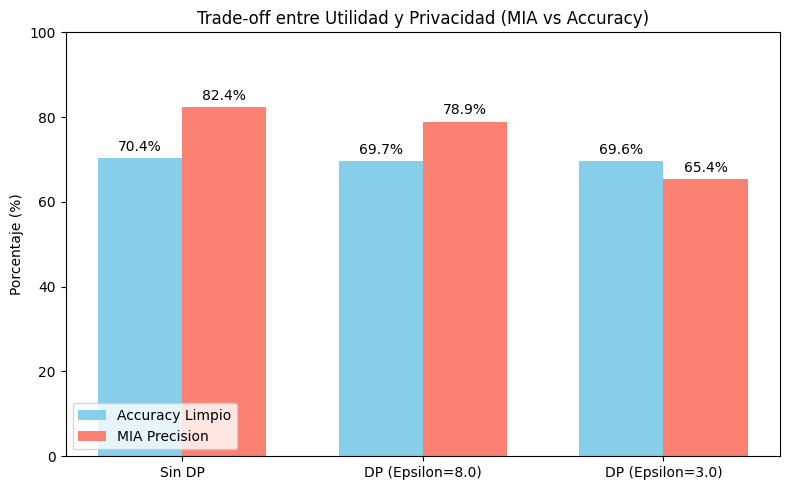

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Crear un DataFrame con los resultados
data = {
    'Escenario': ['Sin DP', 'DP (Epsilon=8.0)', 'DP (Epsilon=3.0)'],
    'Accuracy Limpio (%)': [acc_base, acc_dp_8, acc_dp_3],
    'MIA Precision (%)': [precision_sin_dp * 100, precision_dp_8 * 100, precision_dp_3 * 100],
    'MIA Recall (%)': [recall_sin_dp * 100, recall_dp_8 * 100, recall_dp_3 * 100]
}
df_results = pd.DataFrame(data)
print("\n--- TABLA FINAL DE RESULTADOS ---")
display(df_results.round(2))

# Crear una gráfica de barras agrupadas
x = np.arange(len(df_results['Escenario']))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, df_results['Accuracy Limpio (%)'], width, label='Accuracy Limpio', color='skyblue')
rects2 = ax.bar(x + width/2, df_results['MIA Precision (%)'], width, label='MIA Precision', color='salmon')

ax.set_ylabel('Porcentaje (%)')
ax.set_title('Trade-off entre Utilidad y Privacidad (MIA vs Accuracy)')
ax.set_xticks(x)
ax.set_xticklabels(df_results['Escenario'])
ax.legend(loc='lower left')

ax.set_ylim(0, 100)

# Añadir etiquetas a las barras
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()


### Estudio de Ablación y Conclusiones

*Como se puede observar en la gráfica y la tabla generadas a continuación, al aplicar Privacidad Diferencial (DP) logramos mitigar eficazmente la memorización del modelo. La precisión del atacante (MIA Precision) cae desde más de un 80% en el modelo base hasta valores mucho más bajos (cercanos al 65%) en alta privacidad ($\epsilon=3.0$). Todo esto se consigue a costa de una bajada casi imperceptible en la utilidad principal del modelo (el Accuracy limpio baja menos de 1%).*